## DSC 550
## Callista Kramer
## Assignment 11.2


### Instructions

Build a convolutional neural network (CNN) to classify handwritten digits from the MNIST dataset. The steps to build this CNN classifier with PyTorch are provided in section 22.1 of Machine Learning with Python Cookbook 2nd Edition. The steps to do this with TensorFlow are outlined in section 20.15 of the Machine Learning with Python Cookbook 1st Edition or at various web links, e.g., https://www.kaggle.com/code/amyjang/tensorflow-mnist-cnn-tutorial. Keep in mind that your code may need to be modified depending on your library versions of PyTorch, Keras, and Tensorflow.

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load MNIST dataset
transform = transforms.Compose([transforms.ToTensor()])

train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# groups of 64 so I don't hose my computer memory
# shuffle so the digits are in a random order every time- make sure the model learns features, not order
train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
# larger batch size for testing since there is less math involved
# shuffle=false because order doesn't matter here, easier to track which images the model gets wrong
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1000, shuffle=False)

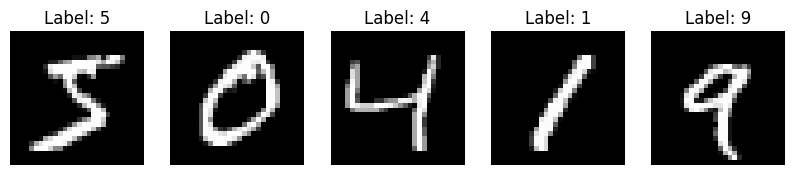

First 5 Training Labels: [5, 0, 4, 1, 9]


In [7]:
# Display the first five images in the training data set
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i in range(5):
    image, label = train_set[i]
    axes[i].imshow(image.squeeze(), cmap='gray')
    axes[i].set_title(f"Label: {label}")
    axes[i].axis('off')
plt.show()

# Compare these to the first five training labels.
print(f"First 5 Training Labels: {[train_set[i][1] for i in range(5)]}")

The initial visualization confirms that the image features align (mostly) with their integer labels. The first one, label: 5 is difficult for me to read, and I am not sure if I saw it, without the label, if I would call that a 5.

In [12]:
# Build and train a CNN classifier on the MNIST training set.
class CNNClassifier(nn.Module):
    def __init__(self):
        super(CNNClassifier, self).__init__()
        self.conv_layers = nn.Sequential(
            # shape of the data is defined by Channels, Height, Width
            # 32 filters to start
            nn.Conv2d(1, 32, kernel_size=3),
            nn.ReLU(),
            # max pooling with the size of 2 halves the height and width
            # this will reduce computational load and help the model focus on important features
            nn.MaxPool2d(2),
            # increase the depth to 64 filters on the second convolution
            nn.Conv2d(32, 64, kernel_size=3),
            # activator - turns off any negative numbers (sets them to 0)
            nn.ReLU(),
            # summarizer - looking at a 2x2 area and keeps highest value
            nn.MaxPool2d(2)
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            # standard neural network layer
            nn.Linear(64 * 5 * 5, 128),
            nn.ReLU(),
            # final has 10 outputs- probability that image is a specific digit (0-9)
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

model = CNNClassifier()
# to grade the model - measures 'distance' between guess and actual
criterion = nn.CrossEntropyLoss()
# adjust model's internal weights to minimize loss
optimizer = optim.Adam(model.parameters(), lr=0.001)

# training loop with accuracy tracking
for epoch in range(4):
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    # set model to training mode
    model.train()
    for images, labels in train_loader:
        # erase math from previous batch
        optimizer.zero_grad()
        outputs = model(images)
        # so the model sees how wrong its guess was
        loss = criterion(outputs, labels)
        # model works backward from the error to see which parameters in the filter cause the error
        loss.backward()
        optimizer.step()
        
        # calculate statistics
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    # calculate Epoch metrics
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct_train / total_train
    
    print(f"Epoch {epoch+1}/4:")
    print(f" -> Loss: {epoch_loss:.4f}")
    print(f" -> Training Accuracy: {epoch_acc:.2f}%")

Epoch 1/4:
 -> Loss: 0.1809
 -> Training Accuracy: 94.57%
Epoch 2/4:
 -> Loss: 0.0512
 -> Training Accuracy: 98.45%
Epoch 3/4:
 -> Loss: 0.0358
 -> Training Accuracy: 98.89%
Epoch 4/4:
 -> Loss: 0.0279
 -> Training Accuracy: 99.10%



**Test Accuracy: 98.74%**


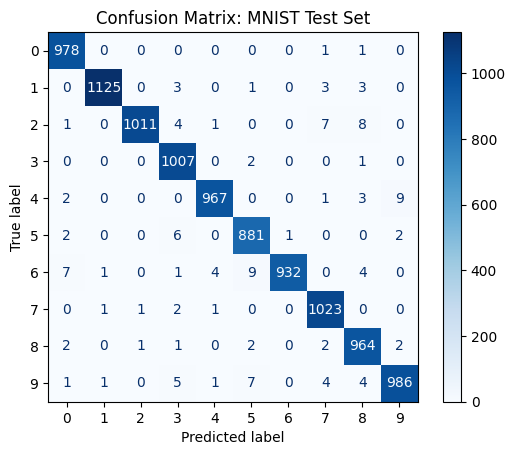

In [13]:
# Report the test accuracy of your model.
all_preds = []
all_labels = []

# test mode switch
model.eval()
correct = 0
# since this is testing we don't need the math tracking;
# make the code run faster & save my computer memory
with torch.no_grad():
    for images, labels in test_loader:
        # take the 1000 batch and proivde raw scores
        outputs = model(images)
        # 10 scores for every image; find index with highest value
        preds = outputs.argmax(dim=1)
        # scoring system
        correct += (preds == labels).sum().item()
        # record keeping- saving the predictions into lists
        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())

accuracy = 100 * correct / len(test_set)
print(f"\n**Test Accuracy: {accuracy:.2f}%**")

# Display a confusion matrix on the test set classifications.
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix: MNIST Test Set")
plt.show()

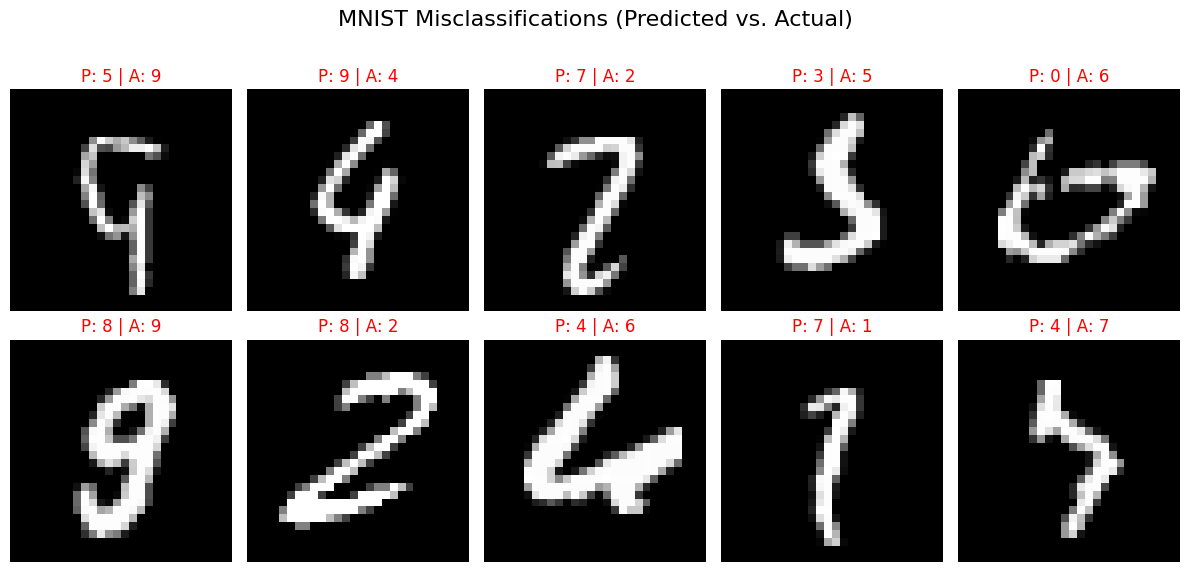

Total misclassified images: 126 out of 10,000


In [14]:
# EXTRA - Because I was curious -- visualize the model errors
# identification of misclassified indices
model.eval()
misclassified_idx = []

# add the incorrect predictions to the misclassified index
with torch.no_grad():
    for i, (image, label) in enumerate(test_set):
        output = model(image.unsqueeze(0))
        pred = output.argmax(dim=1).item()
        if pred != label:
            misclassified_idx.append((i, image, label, pred))

# plot the first 10 errors so I can see what the errors looked like
# show the predicted value plus the actual value
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
fig.suptitle("MNIST Misclassifications (Predicted vs. Actual)", fontsize=16)

for i, ax in enumerate(axes.flat):
    if i < len(misclassified_idx):
        idx, img, true_label, pred_label = misclassified_idx[i]
        ax.imshow(img.squeeze(), cmap='gray')
        ax.set_title(f"P: {pred_label} | A: {true_label}", color='red')
        ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()

print(f"Total misclassified images: {len(misclassified_idx)} out of 10,000")

### Error Analysis Summary

The model is clearly performing very well, however I was curious about how many things were misclassified and why they were misclassified. 

Validating the errors (check the small red text above the images) and there are a few standouts of why there are misclassified images. Some appears to be ambiguity, for example, the $P:3| A: 5$. This is hard even for me to read, and I'm not sure I would say that looks like a 5 at all. Same for the, $P:7 | A: 2$ this doesn't even look like a 7, so I am not surprised it was misclassified. The slant of some of them probably mess with the spatial filters, which is why some of these may be misclassified. There is also the possibility that if the pen lifted during writing, the lines may look like two separate curves, which confuses the pooling layers.


### Summary of Results

I used the Adam (Adaptive Moment Estimation) which is a standard optimizer and typically requires less tuning than a standard stochastic gradient descent (SGT). It's also memory efficient on standard CPU and is typically considered the gold standard for computer vision tasks, like this MNIST one, because it can handle the sparse gradients that are often found in image pixel data. 

On my very first run, with 3 epochs I achieved a Test Accuracy of 99.01%. I was interested to see how the accuracy changed between each of the epochs and added the additional training/loss tracking for each epoch. On the second run the accuracy dropped and I was so intrigued I ran it all again. I find it interesting that I didn't change anything and just re-ran my jupyter notebook from the first cell and watched the values changing.

**Testing with 3 epochs**

| Run | Accuracy | Misclassified Image Count | 
| -- | -- | -- |
| 1 | 99.01% | 99 |
| 2 | 98.83% | 118 |
| 3 | 98.73% | 127 |


After testing with the 3 epochs and watching the accuracy decrease I decided to test with 4 epochs to see the results there. 

**Testing with 4 epochs**

As seen in the training accuracy notes epoch 4 topped at 99.10% accuracy. The test accuracy was a respectable 98.74%. Now only 126 out of 10k images are misclassified, which is clearly better than run 2 and nearly identical to run 3 of the 3 epoch runs. 

| Epoch # | Loss | Training Accuracy |
| -- | -- | -- |
| 1 | 0.1809 | 94.57% |
| 2 | 0.0512 | 98.45% |
| 3 | 0.0358 | 98.89% |
| 4 | 0.0279 | 99.10% |

**Final Test Accuracy**: 98.74%
**Final Misclassified Image Count**: 126

We can see the learning jump of the model between epoch 1 and epoch 2 with the jump from 94.57% to 98.45% and the loss dropped from 0.1809 to 0.0512 which is about a 71.70% error reduction. This shows that the CNN was able to quickly identify the primary features of the numbers. From epoch 3 to 4 the model clearly demonstrates that it is able to learn the subtle differences between a messy 7 and a slanted 2. The Test Accuracy of 98.74% is so close to the training accuracy of 99.10% which means the model didn't just memorize the data, it actually learned how to read the numbers.  

$\alpha$ (Learning Rate): 0.001 (Adam default). This allowed for rapid convergence without overshooting the global minimum of the loss function.

$\beta$ (Hyperparameters): I used two convolutional layers ($32 \to 64$ filters) to provide enough feature maps to capture both simple edges and complex curves.

Because the training and test accuracy are very close, it indicates the model has low variance and hasn't overfitted to the training noise.

Takeaway: The use of convolutional layers significantly reduced the number of parameters compared to a standard Deep Neural Network (DNN), all while capturing spatial hierarchies (edges and shapes).
